# Parkinson's Disease Detection

**Made by:**

TS SHARAN-25BCA7670

SJ VISWAK-25BCE7873

# Mounting Google Drive

In [211]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Define Dataset Paths

In [212]:
spiral_train_path = "/content/drive/MyDrive/Parkinson_Disease_Detection/Spiral/Train"
spiral_test_path  = "/content/drive/MyDrive/Parkinson_Disease_Detection/Spiral/Test"
wave_train_path = "/content/drive/MyDrive/parkinson_dataset/wave/train"
wave_test_path    = "/content/drive/MyDrive/Parkinson_Disease_Detection/Wave/Test"

# Spiral Model:

**Processing**

In [213]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

img_height, img_width = 224, 224
batch_size = 16
SEED = 42
tf.keras.utils.set_random_seed(SEED)

def get_class_weights(ds):
    ys = np.concatenate([y.numpy().ravel() for _, y in ds])
    n, pos = len(ys), ys.sum()
    return {0: n / (2 * (n - pos)), 1: n / (2 * pos)}

**Train**

In [214]:
spiral_train = tf.keras.utils.image_dataset_from_directory(
    spiral_train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

spiral_val = tf.keras.utils.image_dataset_from_directory(
    spiral_train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

class_names = spiral_train.class_names
print(class_names)

Found 73 files belonging to 2 classes.
Using 59 files for training.
Found 73 files belonging to 2 classes.
Using 14 files for validation.
['Healthy', 'Parkinson']


**Test**

In [215]:
spiral_test = tf.keras.utils.image_dataset_from_directory(
    spiral_test_path,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary",
    shuffle=False
)

Found 30 files belonging to 2 classes.


**Data Augmentation**

In [216]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.2),
])

**EfficientNetB0 base**

In [217]:
base_model_spiral = tf.keras.applications.EfficientNetB0(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights="imagenet"
)
base_model_spiral.trainable = False   # Phase 1: frozen

**Build Model**

In [218]:
inputs = layers.Input(shape=(img_height, img_width, 3))
x = data_augmentation(inputs)
x = base_model_spiral(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(64, activation="relu",
                 kernel_regularizer=tf.keras.regularizers.l2(1e-3))(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

spiral_model = models.Model(inputs, outputs)

**Compile**

In [219]:
spiral_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

**Train**

In [220]:
spiral_cw = get_class_weights(spiral_train)

callbacks_1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=3, factor=0.5)
]

spiral_history1 = spiral_model.fit(
    spiral_train, validation_data=spiral_val,
    epochs=40, class_weight=spiral_cw, callbacks=callbacks_1
)

Epoch 1/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.5254 - loss: 0.8020 - val_accuracy: 0.5000 - val_loss: 0.8377 - learning_rate: 0.0010
Epoch 2/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.6441 - loss: 0.7006 - val_accuracy: 0.5714 - val_loss: 0.7537 - learning_rate: 0.0010
Epoch 3/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.7458 - loss: 0.6643 - val_accuracy: 0.7143 - val_loss: 0.7073 - learning_rate: 0.0010
Epoch 4/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.7458 - loss: 0.6519 - val_accuracy: 0.5714 - val_loss: 0.7425 - learning_rate: 0.0010
Epoch 5/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.7458 - loss: 0.6605 - val_accuracy: 0.5714 - val_loss: 0.7962 - learning_rate: 0.0010
Epoch 6/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.7966 - loss: 0.5636 - val_accuracy: 0.5714 - val_loss: 0.7721 - learning_rate: 0.0010
Epoch 7/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.7458 - loss: 0.6203 - val_accuracy: 0.5714 - val_loss: 0

**Fine-tune last 30 layers**

In [197]:
base_model_spiral.trainable = True
for layer in base_model_spiral.layers[:-30]:
    layer.trainable = False
for layer in base_model_spiral.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False   # keep BatchNorm frozen

spiral_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

callbacks_2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
]

spiral_history2 = spiral_model.fit(
    spiral_train, validation_data=spiral_val,
    epochs=40, class_weight=spiral_cw, callbacks=callbacks_2
)

Epoch 1/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.8305 - loss: 0.4990 - val_accuracy: 0.5714 - val_loss: 0.6982
Epoch 2/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.7627 - loss: 0.5429 - val_accuracy: 0.5714 - val_loss: 0.7273
Epoch 3/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.7966 - loss: 0.5497 - val_accuracy: 0.5714 - val_loss: 0.7585
Epoch 4/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.7797 - loss: 0.5238 - val_accuracy: 0.5714 - val_loss: 0.7837
Epoch 5/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.7966 - loss: 0.5255 - val_accuracy: 0.5714 - val_loss: 0.7977
Epoch 6/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.7797 - loss: 0.5713 - val_accuracy: 0.5714 - val_loss: 0.8020
Epoch 7/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.7966 - loss: 0.5479 - val_accuracy: 0.5714 - val_loss: 0.7958
Epoch 8/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.8305 - loss: 0.5220 - val_accuracy: 0.5714 - val_loss: 0.7862
Epoch 9/40


**Evaluation**

In [198]:
loss, acc = spiral_model.evaluate(spiral_test, verbose=0)
print(f"Spiral Test Accuracy: {acc:.3f}")

y_true = np.concatenate([y.numpy().ravel() for _, y in spiral_test]).astype(int)
spiral_probs = spiral_model.predict(spiral_test, verbose=0).ravel()
y_pred = (spiral_probs > 0.5).astype(int)

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=class_names))

Spiral Test Accuracy: 0.767
[[14  1]
 [ 6  9]]
              precision    recall  f1-score   support

     Healthy       0.70      0.93      0.80        15
   Parkinson       0.90      0.60      0.72        15

    accuracy                           0.77        30
   macro avg       0.80      0.77      0.76        30
weighted avg       0.80      0.77      0.76        30



**Saving Model**

In [199]:
spiral_model.save("/content/drive/MyDrive/Parkinson_Disease_Detection/Spiral_Model.h5")

# Wave Model:

**Train**

In [200]:
# Correcting the path to match the Parkinson_Disease_Detection folder structure
wave_train_path = "/content/drive/MyDrive/Parkinson_Disease_Detection/Wave/Train"

wave_train = tf.keras.utils.image_dataset_from_directory(
    wave_train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

wave_val = tf.keras.utils.image_dataset_from_directory(
    wave_train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

Found 72 files belonging to 2 classes.
Using 58 files for training.
Found 72 files belonging to 2 classes.
Using 14 files for validation.


**Test**

In [201]:
wave_test = tf.keras.utils.image_dataset_from_directory(
    wave_test_path,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary",
    shuffle=False
)

Found 30 files belonging to 2 classes.


**EfficientNetB0 base**

In [202]:
base_model_wave = tf.keras.applications.EfficientNetB0(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights="imagenet"
)
base_model_wave.trainable = False   # Phase 1: frozen

**Build Model**


In [203]:
inputs = layers.Input(shape=(img_height, img_width, 3))
x = data_augmentation(inputs)
x = base_model_wave(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(64, activation="relu",
                 kernel_regularizer=tf.keras.regularizers.l2(1e-3))(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

wave_model = models.Model(inputs, outputs)

**Compile**

In [204]:
wave_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

**Model Training**

In [205]:
wave_cw = get_class_weights(wave_train)

callbacks_1 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=3, factor=0.5)
]

wave_history1 = wave_model.fit(
    wave_train, validation_data=wave_val,
    epochs=40, class_weight=wave_cw, callbacks=callbacks_1
)

Epoch 1/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.4828 - loss: 0.8710 - val_accuracy: 0.5000 - val_loss: 0.8017 - learning_rate: 0.0010
Epoch 2/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.6034 - loss: 0.7623 - val_accuracy: 0.5714 - val_loss: 0.7565 - learning_rate: 0.0010
Epoch 3/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.6379 - loss: 0.7416 - val_accuracy: 0.6429 - val_loss: 0.7587 - learning_rate: 0.0010
Epoch 4/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.7759 - loss: 0.6240 - val_accuracy: 0.5714 - val_loss: 0.7707 - learning_rate: 0.0010
Epoch 5/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.7069 - loss: 0.7446 - val_accuracy: 0.7143 - val_loss: 0.7519 - learning_rate: 0.0010
Epoch 6/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.6897 - loss: 0.6601 - val_accuracy: 0.6429 - val_loss: 0.7002 - learning_rate: 0.0010
Epoch 7/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8793 - loss: 0.5355 - val_accuracy: 0.6429 - val_loss: 0

**Fine-tune last 30 layers**

In [206]:
base_model_wave.trainable = True
for layer in base_model_wave.layers[:-30]:
    layer.trainable = False
for layer in base_model_wave.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

wave_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

callbacks_2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
]

wave_history2 = wave_model.fit(
    wave_train, validation_data=wave_val,
    epochs=40, class_weight=wave_cw, callbacks=callbacks_2
)

Epoch 1/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.8793 - loss: 0.4646 - val_accuracy: 0.7857 - val_loss: 0.5752
Epoch 2/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.8966 - loss: 0.4603 - val_accuracy: 0.7857 - val_loss: 0.5761
Epoch 3/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.9138 - loss: 0.3992 - val_accuracy: 0.7857 - val_loss: 0.5841
Epoch 4/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.8276 - loss: 0.5032 - val_accuracy: 0.7857 - val_loss: 0.5931
Epoch 5/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.8103 - loss: 0.4653 - val_accuracy: 0.7857 - val_loss: 0.6028
Epoch 6/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.8448 - loss: 0.4844 - val_accuracy: 0.7857 - val_loss: 0.6113
Epoch 7/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.8448 - loss: 0.4723 - val_accuracy: 0.7857 - val_loss: 0.6178
Epoch 8/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8276 - loss: 0.5395 - val_accuracy: 0.7857 - val_loss: 0.6187
Epoch 9/40
4/4

**Evaluate**

In [207]:
loss, acc = wave_model.evaluate(wave_test, verbose=0)
print(f"Wave Test Accuracy: {acc:.3f}")

y_true_w = np.concatenate([y.numpy().ravel() for _, y in wave_test]).astype(int)
wave_probs = wave_model.predict(wave_test, verbose=0).ravel()
y_pred_w = (wave_probs > 0.5).astype(int)

print(confusion_matrix(y_true_w, y_pred_w))
print(classification_report(y_true_w, y_pred_w, target_names=class_names))

Wave Test Accuracy: 0.900
[[14  1]
 [ 2 13]]
              precision    recall  f1-score   support

     Healthy       0.88      0.93      0.90        15
   Parkinson       0.93      0.87      0.90        15

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



**Saving Model**

In [208]:
wave_model.save("/content/drive/MyDrive/Parkinson_Disease_Detection/Wave_model.h5")

**Accuracy**

In [209]:
print(f"Spiral Test Accuracy: {((spiral_probs > 0.5).astype(int) == y_true).mean():.3f}")
print(f"Wave Test Accuracy:   {((wave_probs > 0.5).astype(int) == y_true_w).mean():.3f}")

# Optional ensemble: only valid if both test folders have the same patients in the same order
if len(y_true) == len(y_true_w) and (y_true == y_true_w).all():
    ens = (((spiral_probs + wave_probs) / 2) > 0.5).astype(int)
    print(f"Ensemble Test Accuracy: {(ens == y_true).mean():.3f}")

Spiral Test Accuracy: 0.767
Wave Test Accuracy:   0.900
Ensemble Test Accuracy: 0.867


**Visualizing Accuracy**

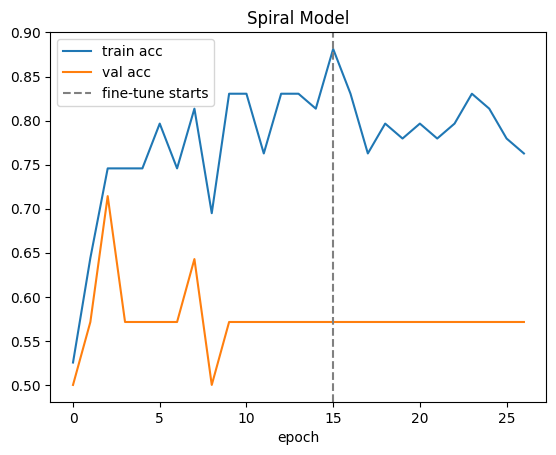

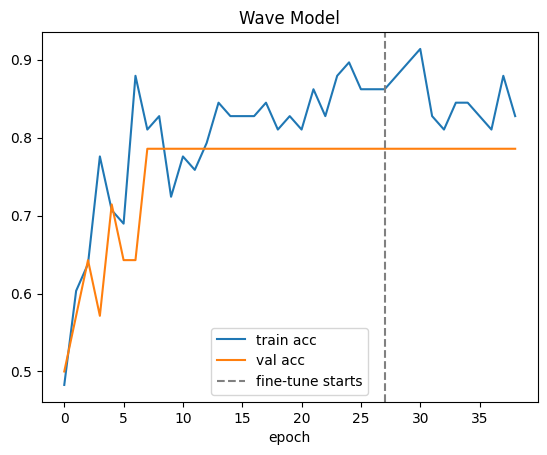

In [210]:
def plot_history(h1, h2, title):
    acc  = h1.history["accuracy"] + h2.history["accuracy"]
    vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
    plt.plot(acc, label="train acc")
    plt.plot(vacc, label="val acc")
    plt.axvline(len(h1.history["accuracy"]) - 1, color="gray", linestyle="--", label="fine-tune starts")
    plt.title(title)
    plt.xlabel("epoch")
    plt.legend()
    plt.show()

plot_history(spiral_history1, spiral_history2, "Spiral Model")
plot_history(wave_history1, wave_history2, "Wave Model")